In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Analysis and visualisation of benchmarking results

This notebook treats the analysis and visualisation of metrics-based benchmarking results as generated by the Snakemake pipeline.

## Preliminaries and data loading

The real and synthetic datasets utilised in the benchmark are the following: 

In [2]:
real_datasets = ['osmFISH_Codeluppi', 'MERFISH_Moffitt', 'MERFISH_Zhang', 'STARmap_Wang', 'Slide-seq_Langlieb', 'Slide-seqV2_Lan', 'StereoSeq_Chen', '10xVisium_Fu', '10xVisium_Maynard', 'ST_Stahl']
synth_datasets = ['synth-close', 'synth-circles', 'synth-moons', 'synth-varied', 'synth-blobs', 'synth-trials', 'synth-2blobs', 'synth-3stripes']

Scores in a host of metrics are generated through the Snakemake pipeline for all method/sample combinations, and saved in the `results/scores.csv` file. 

In [3]:
from plotting_utils import load_and_annotate_scores
scores_df = load_and_annotate_scores('real')  # loading scores from all methods on "real" datasets
scores_df

,dataset,sample,method,ARI,FM,NMI,AMI,ACC,AC,BAC,...,RAS,SI_X,DBS_X,CHAOS_X,PAS_X,RAS_X,num_NA,technology,tech_type,exp
0,ST_Stahl,mouse_brain_olfactory_bulb_ST_slide_0,ADEPT,0.193398,0.488499,0.278087,0.265674,0.509363,0.509363,0.453326,...,0.456929,0.081326,10.457470,0.641624,0.232210,0.307116,0.0,ST,low-res,None
1,ST_Stahl,mouse_brain_olfactory_bulb_ST_slide_1,ADEPT,0.940341,0.955492,0.926842,0.925961,0.975000,0.975000,0.974023,...,0.932143,0.671342,0.509347,0.375649,0.025000,0.025000,0.0,ST,low-res,None
2,ST_Stahl,mouse_brain_olfactory_bulb_ST_slide_2,ADEPT,0.340435,0.534426,0.507667,0.501096,0.516729,0.516729,0.568879,...,0.691450,-0.036588,3.881235,0.407314,0.289963,0.375465,0.0,ST,low-res,None
3,ST_Stahl,mouse_brain_olfactory_bulb_ST_slide_3,ADEPT,0.464480,0.606679,0.522514,0.516297,0.742424,0.742424,0.745271,...,0.931818,0.157149,2.367335,0.562429,0.231061,0.265152,0.0,ST,low-res,None
4,ST_Stahl,mouse_brain_olfactory_bulb_ST_slide_4,ADEPT,0.285701,0.517371,0.404452,0.395446,0.471910,0.471910,0.432081,...,0.509363,0.000968,5.272716,0.637831,0.303371,0.355805,0.0,ST,low-res,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46295,StereoSeq_Chen,E10,consensus,0.408206,0.456458,0.665325,0.663199,0.560866,0.560866,0.625778,...,0.279020,0.200056,1.920153,0.681214,0.161290,0.181540,0.0,StereoSeq,high-res,None
46297,StereoSeq_Chen,E9,consensus,0.456170,0.506994,0.660844,0.658666,0.593915,0.593915,0.584289,...,0.185752,0.295916,1.133078,0.518826,0.131519,0.147392,0.0,StereoSeq,high-res,None
46299,StereoSeq_Chen,E11,consensus,0.547489,0.588109,0.710101,0.709598,0.648751,0.648751,0.660716,...,0.097314,0.237979,1.470722,0.650639,0.159253,0.175315,0.0,StereoSeq,high-res,None
46300,Slide-seqV2_Lan,puck_230517_36,consensus,0.463003,0.631511,0.573090,0.572871,0.651964,0.651964,0.613106,...,0.115265,0.413876,0.851245,0.530043,0.089852,0.093987,0.0,Slide-seqV2,high-res,None


## Visualising domain label outputs

We provide a set of functions to visualise method outputs. 

In [4]:
from plotting_utils import plot_spots, plot_spots_multilabels

from workflow.scripts.aggregate import load_coords, load_labels, get_assignments

labels are not (castable to) integers


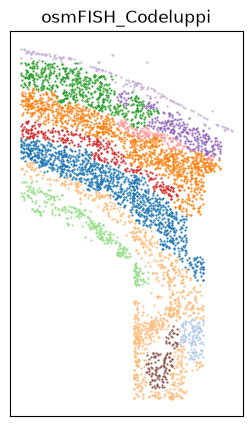

In [5]:
coords_df = load_coords('osmFISH_Codeluppi', 'correctedsample')
labels_df = load_labels('osmFISH_Codeluppi', 'correctedsample')
fig, ax = plt.subplots(figsize=(3, 5))
plot_spots(coords_df, labels_df['gt'].rename('osmFISH_Codeluppi'), colours=plt.cm.tab20.colors, ax=ax)

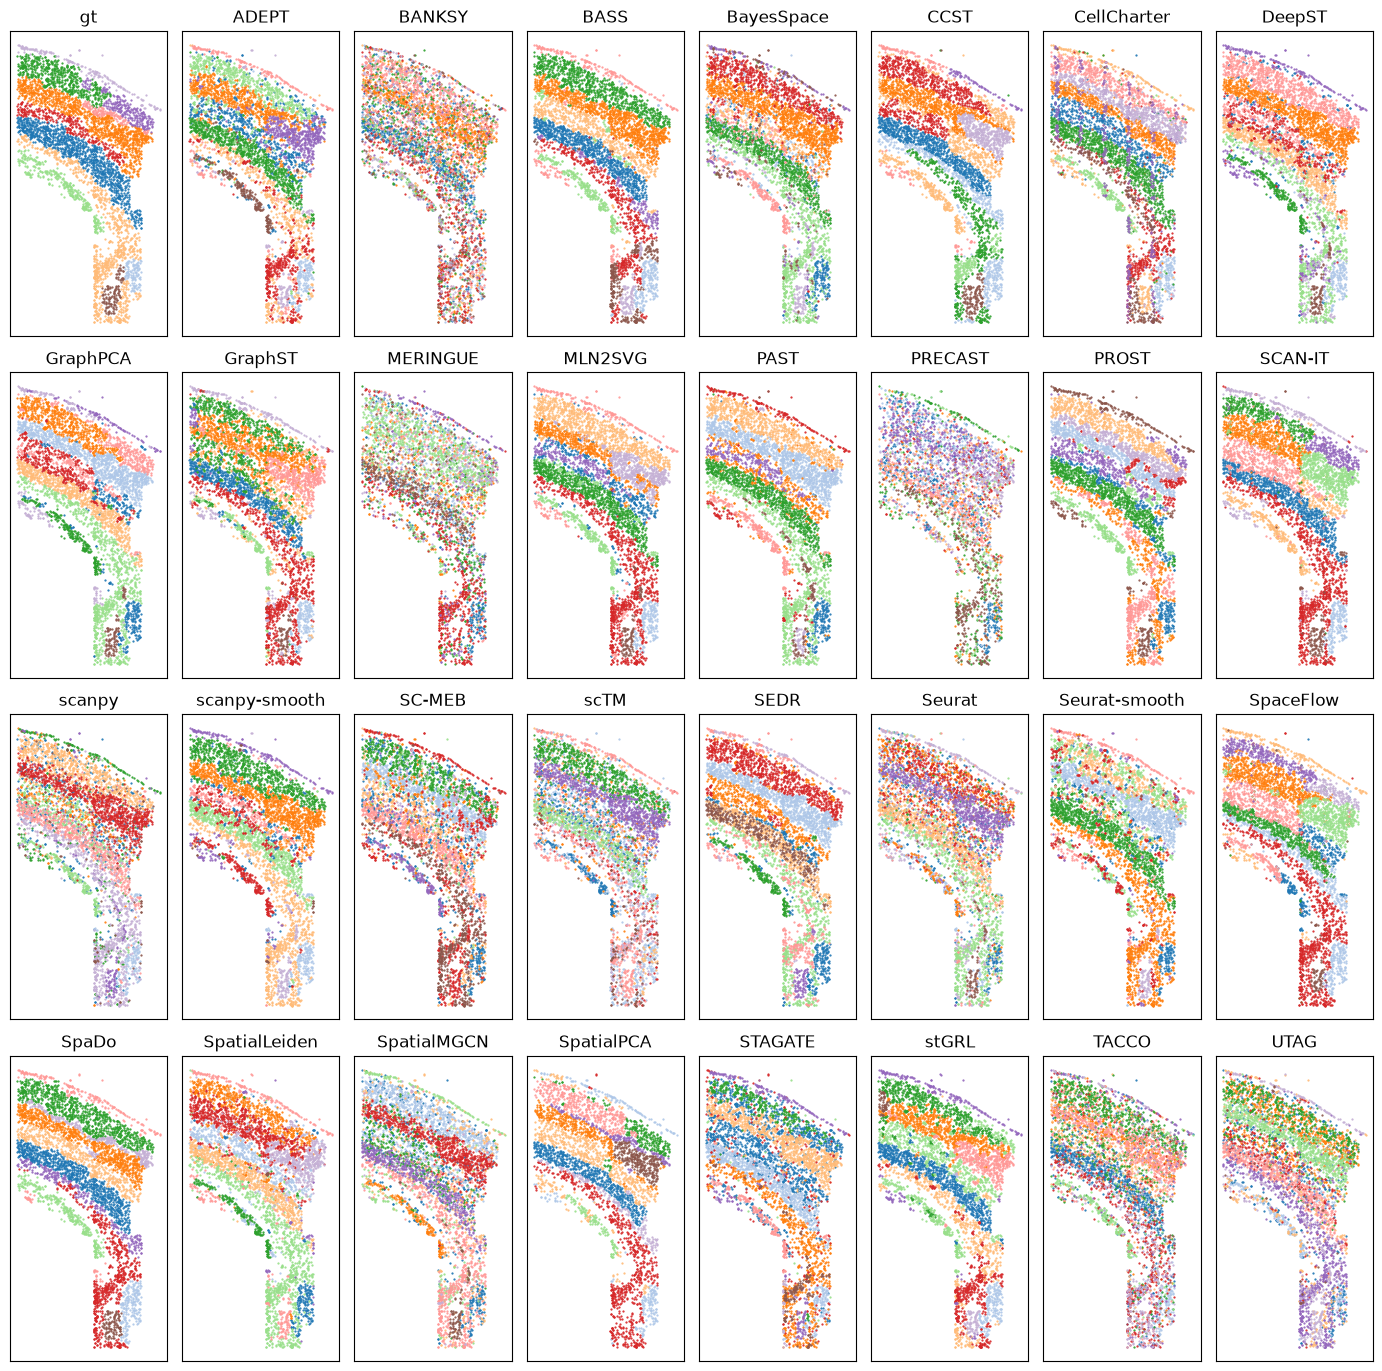

In [6]:
coords_df, all_labels_df = get_assignments('osmFISH_Codeluppi', 'correctedsample')
plot_spots_multilabels(coords_df, all_labels_df, colours=plt.cm.tab20.colors, max_ncols=8, ratio_mod=2)

## Reproducing figures

The following sections allow the reproduction of relevant plots for the results figures in our manuscript. 

### Figure 2

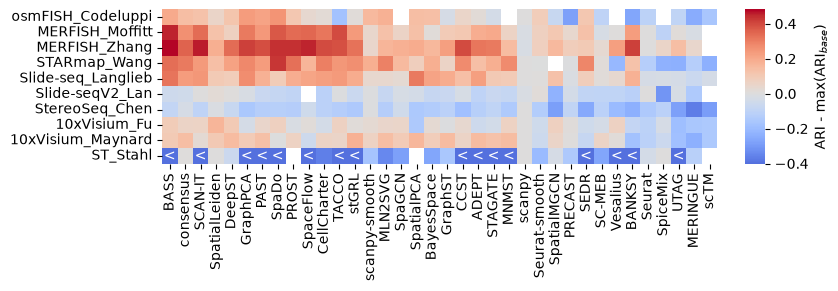

In [7]:
plotdf = scores_df.pivot_table(values='ARI', index='method', columns='dataset', aggfunc='mean')
plotdf = plotdf - plotdf.loc[['scanpy','Seurat']].max()
method_order = plotdf.apply(lambda col: (col-col.mean())/col.std()).mean(axis=1).sort_values(ascending=False).index.tolist()
plotdf = plotdf.loc[method_order, real_datasets]
from plotting_utils import plot_heatmap_fig2
plot_heatmap_fig2(plotdf)
plt.show()

/home/dea09366/spatialdomains/official_github/plotting_utils.py:97: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  pvalue = mannwhitneyu(aris_visium, aris_merfish).pvalue


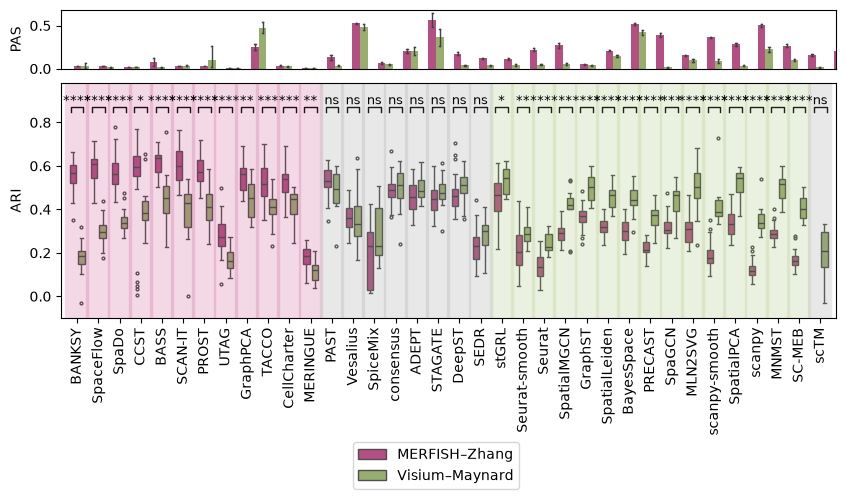

In [8]:
from plotting_utils import plot_merfish_visium_fig2
plot_merfish_visium_fig2(scores_df)

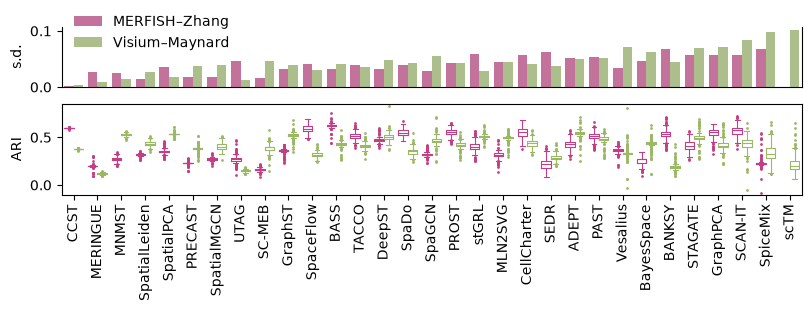

In [9]:
from plotting_utils import plot_stability_fig2
plot_stability_fig2(load_and_annotate_scores('all'))

### Figure 3

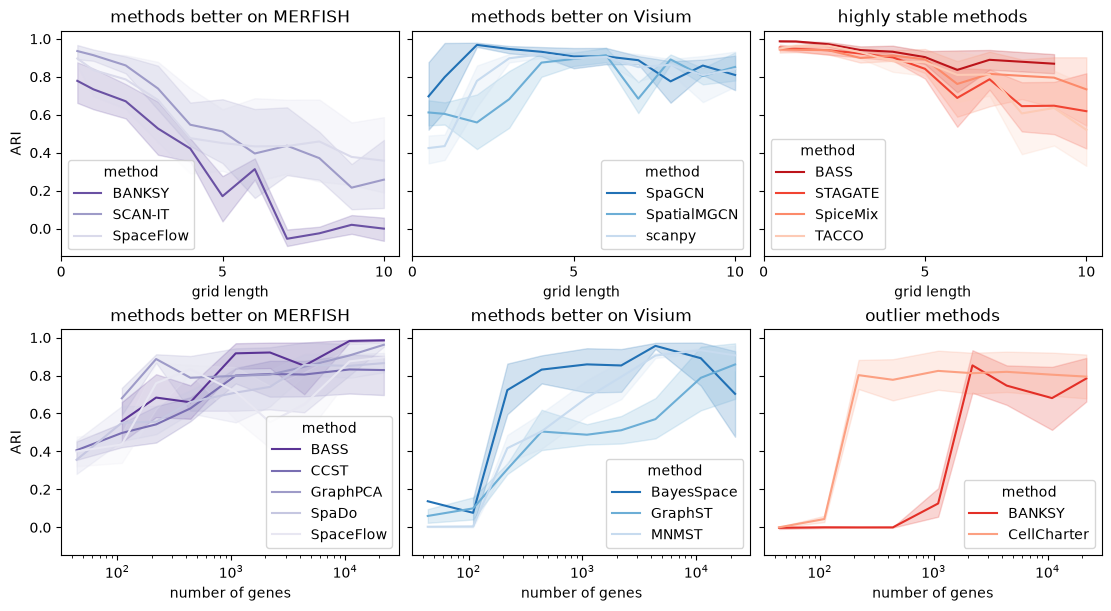

In [10]:
from plotting_utils import load_synth_scores
synthdf = load_synth_scores()
plotdf = synthdf[synthdf['exp']=='exp8'].copy()
fig, axes = plt.subplots(ncols=3, nrows=2, sharey=True, figsize=(11, 6), layout='constrained')
sns.lineplot(plotdf[plotdf['method'].isin(['BANKSY','SpaceFlow','SCAN-IT'])], x='exp8length', y='ARI', hue='method', estimator='mean', palette='Purples_r', err_style='band', ax=axes[0][0])
sns.lineplot(plotdf[plotdf['method'].isin(['SpatialMGCN','SpaGCN','scanpy'])], x='exp8length', y='ARI', hue='method', estimator='mean', palette='Blues_r', err_style='band', ax=axes[0][1])
sns.lineplot(plotdf[plotdf['method'].isin(['BASS','TACCO','STAGATE','SpiceMix'])], x='exp8length', y='ARI', hue='method', estimator='mean', palette='Reds_r', err_style='band', ax=axes[0][2])
for ax, title in zip(axes[0], ['methods better on MERFISH', 'methods better on Visium', 'highly stable methods']):
    ax.set_xlabel('grid length')
    ax.set_xticks([0, 5, 10])
    ax.set_title(title)

plotdf = synthdf[synthdf['exp']=='exp6'].copy()
plotdf['exp6_ngenes'] = 21899*plotdf['exp6prop']
sns.lineplot(plotdf[plotdf['method'].isin(['SpaceFlow','SpaDo','BASS','CCST','GraphPCA'])], x='exp6_ngenes', y='ARI', hue='method', estimator='mean', palette='Purples_r', err_style='band', ax=axes[1][0])
sns.lineplot(plotdf[plotdf['method'].isin(['GraphST','BayesSpace','MNMST'])], x='exp6_ngenes', y='ARI', hue='method', estimator='mean', palette='Blues_r', err_style='band', ax=axes[1][1])
sns.lineplot(plotdf[plotdf['method'].isin(['BANKSY','CellCharter'])], x='exp6_ngenes', y='ARI', hue='method', estimator='mean', palette='Reds_r', err_style='band', ax=axes[1][2])
for ax, title in zip(axes[1], ['methods better on MERFISH', 'methods better on Visium', 'outlier methods']):
    ax.set_xlabel('number of genes')
    ax.set_xscale('log')
    ax.set_title(title)

plt.show()

### Figure 4

100%|██████████| 6/6 [00:00<00:00,  8.06it/s]


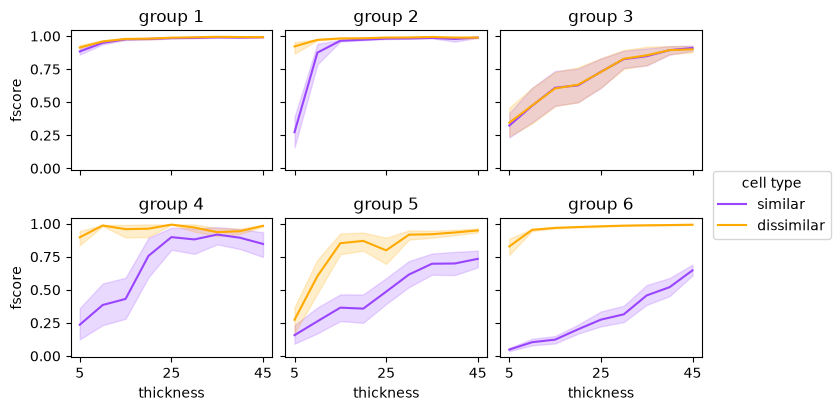

In [11]:
import pickle
with open('results/thickness_fscores.pickle', 'rb') as file:
    fscores = pickle.load(file)
fscores_df = pd.concat(fscores, names=['expname', 'div', 'sd'])
fscores_df = fscores_df.set_index([fscores_df.index, 'method'])

from plotting_utils import plot_thickness_fscores_fig4
plot_thickness_fscores_fig4(fscores_df)

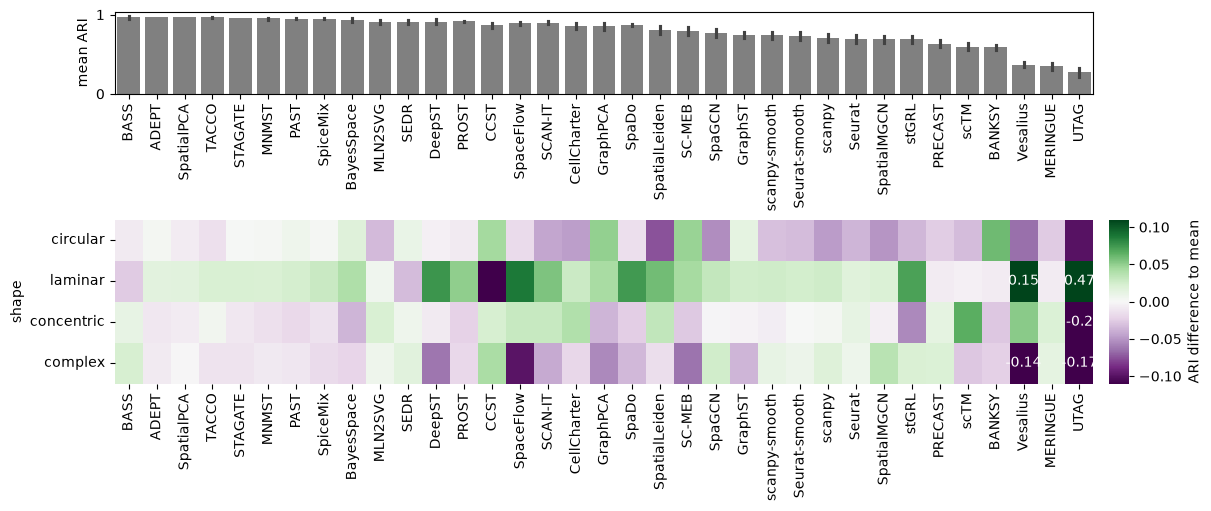

In [12]:
from plotting_utils import plot_shapedependence_fig4
synthdf = load_synth_scores()
plot_shapedependence_fig4(synthdf)

### Runtime / Memory

Text(0, 0.5, 'Memory [MB]')

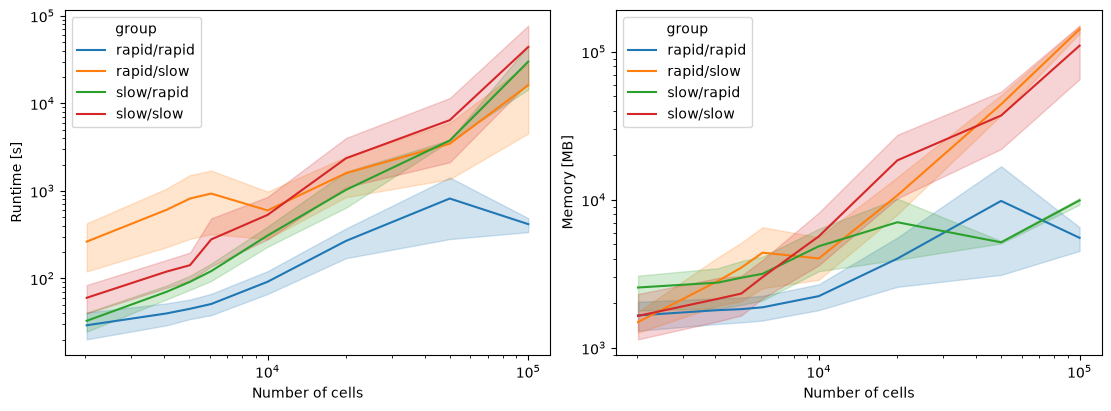

In [14]:
benchmark_df = pd.read_csv('results/benchmark_data.csv')
method_groups = {'ADEPT': 'rapid/rapid', 'BANKSY': 'rapid/rapid', 'CellCharter': 'rapid/rapid', 'PAST': 'rapid/rapid', 'STAGATE': 'rapid/rapid', 'SpaceFlow': 'rapid/rapid', 'TACCO': 'rapid/rapid', 
                 'BASS': 'rapid/slow', 'BayesSpace': 'rapid/slow', 'CCST': 'rapid/slow', 'PRECAST': 'rapid/slow', 'SEDR': 'rapid/slow', 'SpaDo': 'rapid/slow', 'SpiceMix': 'rapid/slow', 
                 'DeepST': 'slow/rapid', 'SC-MEB': 'slow/rapid', 'SpatialMGCN': 'slow/rapid', 
                 'GraphPCA': 'slow/slow', 'GraphST': 'slow/slow', 'MERINGUE': 'slow/slow', 'MNMST': 'slow/slow', 'SCAN-IT': 'slow/slow', 'SpaGCN': 'slow/slow', 'SpatialPCA': 'slow/slow', 'UTAG': 'slow/slow',
                 'MLN2SVG': 'rapid/rapid', 'PROST': 'slow/slow', 'scTM': 'slow/slow', 'stGRL': 'rapid/rapid', 'SpatialLeiden': 'slow/slow'}
benchmark_df['group'] = benchmark_df['method'].map(method_groups)

fig, axes = plt.subplots(ncols=2, figsize=(11, 4), layout='constrained')
sns.lineplot(benchmark_df, x='size', y='s', hue='group', ax=axes[0])
sns.lineplot(benchmark_df, x='size', y='max_rss', hue='group', ax=axes[1])
for ax in axes:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Number of cells')
axes[0].set_ylabel('Runtime [s]')
axes[1].set_ylabel('Memory [MB]')